# 01 - Exploratory data analysis
What does demand look like, and which patterns must the model capture?

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 160
from src.config import connect, SCHEMA
con = connect(read_only=True)

1000 days, 1,222,947 units, $6,329,980 revenue


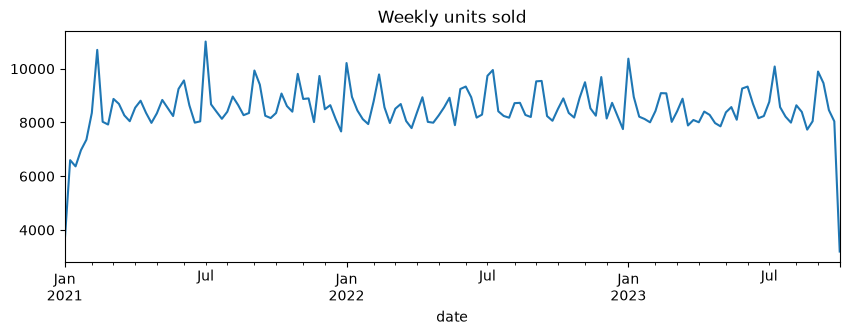

In [2]:
daily = con.execute(f"""select d.full_date as date, sum(f.units_sold) units, sum(f.revenue) revenue
 from {SCHEMA}.fact_sales f join {SCHEMA}.dim_date d using (date_key) group by 1 order by 1""").df()
daily['date'] = pd.to_datetime(daily['date'])
print(f"{len(daily)} days, {daily.units.sum():,.0f} units, ${daily.revenue.sum():,.0f} revenue")
daily.set_index('date').units.resample('W').sum().plot(figsize=(10,3), title='Weekly units sold'); plt.show()

## Weekly seasonality and category mix

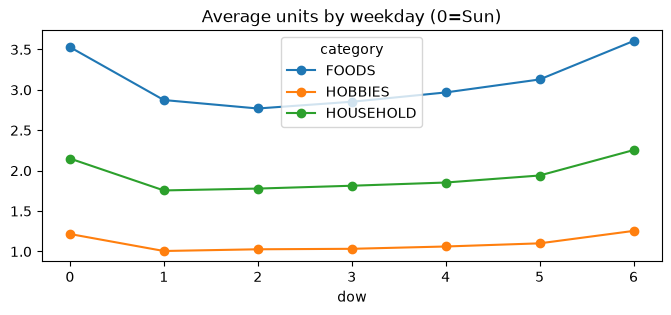

In [3]:
dow = con.execute(f"""select p.category, dayofweek(d.full_date) dow, avg(f.units_sold) avg_units
 from {SCHEMA}.fact_sales f join {SCHEMA}.dim_date d using (date_key) join {SCHEMA}.dim_product p using (product_key)
 group by 1,2""").df().pivot(index='dow', columns='category', values='avg_units')
dow.plot(figsize=(8,3), marker='o', title='Average units by weekday (0=Sun)'); plt.show()

## Holiday effect: demand index around events (FOODS vs others)

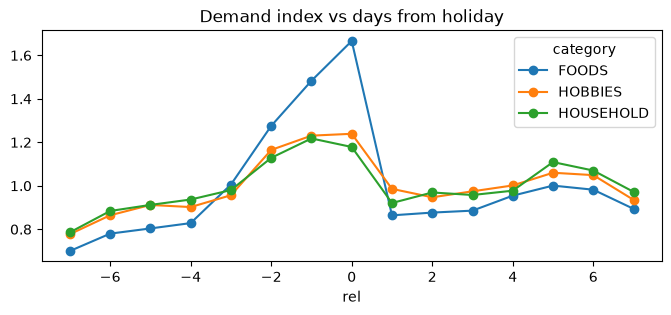

In [4]:
ev = con.execute(f"""
 with e as (select full_date ed from {SCHEMA}.dim_date where event_name is not null and event_name <> 'Christmas'),
 x as (select p.category, datediff('day', e.ed, d.full_date) rel, sum(f.units_sold) u
       from {SCHEMA}.fact_sales f join {SCHEMA}.dim_date d using (date_key) join {SCHEMA}.dim_product p using (product_key)
       join e on abs(datediff('day', e.ed, d.full_date)) <= 7 group by 1,2)
 select * from x""").df()
ev['idx'] = ev.groupby('category').u.transform(lambda s: s / s.mean())
ev.pivot(index='rel', columns='category', values='idx').plot(figsize=(8,3), marker='o', title='Demand index vs days from holiday'); plt.show()

## Intermittency

In [5]:
m = con.execute(f"select product_key, store_key, avg(units_sold) m, avg((units_sold=0)::int) zero_share from {SCHEMA}.fact_sales group by 1,2").df()
print(f"slow movers (<1 unit/day): {(m.m<1).mean():.1%} of series; mean zero-sales share among them: {m[m.m<1].zero_share.mean():.1%}")

slow movers (<1 unit/day): 30.5% of series; mean zero-sales share among them: 65.6%
